## 1. RNN의 한계  

### 1-1. Attention의 등장    

- Attention의 등장 배경 : Seq2Seq의 병목현상  

기존 모델 Seq2Seq은 Context Vector의 크기가 고정되어 있어 입력이 몇단어든 상관없이  같은 크기의 벡터에 모든 정보를 담아야 함.  
디코더는 Context Vector 하나만을 이용해 출력 문장을 생성하기 때문에 문장이 길어질수록 정보손실의 문제도 발생   
Context Vector는 인코더의 마지막 hidden state이므로 마지막 단어의 정보는 진하게 남지만 앞쪽 단어 정보는 여러 단계를 거치며 희미해지는 문제 발생  

-> 이러한 한계를 해결하기 위해 등장 한 것이 Attention!  
 Attention은 디코더가 단어를 생성할 때마다 입력 문장 전체를 다시 보고, 현재 단어와 관련 있는 부분에 집중하여 출력 단어마다 새로운 Context Vector를 생성  

> Def of Attention : 현재 시점에서 가장 중요한 부분에 더 높은 가중치를 부여하는 기술, 출력 단어를 생성할 때 입력 문장 속 단어들 중 어떤 단어에 더 집중할지 정도 결정  

- Attention의 과정  

1. 입력을 벡터 형태로 변환 : 입력 단어를 컴퓨터가 읽을 수 있도록 숫자로 이루어진 벡터로 변환  

2. 단어별 중요도 계산  
    - 관련도 점수 - 현재 작업과 각 단어 사이의 관계가 얼마나 관련이 높고 유사한지 점수를 매김, 이후 이를 Softmax함수를 통해 반환(이때, 비율을 Attention Weight)  

3. 중요도에 따른 입력 정보 조합 : Attention Weight만큼 각 단어의 Hidden state정보를 섞어 Context Vector 생성. 이때, 가장 비율이 높은 단어 정보를 위주로 반영하여 다음 결과 구성   


- Attention 메커니즘의 장점  

1. 시간 경과에 대한 유연성(Vs RNN)  
    - RNN은 멀리 떨어진 단어일수록 정보가 흐려지는 장기 의존성 문제가 있는 반면, Attnetion은 모든 단어를 직접 비교하므로 거리와 상관없이 관계 파악 가능  

2. 공간에 대한 유연성(vs CNN)  
    - CNN은 고정된 크기 필터로 주변정보만 보는 반면, Attention은 모든 위치를 직접 연결하여 한 번에 Global한 관계를 학습 가능  

3. 병렬화(vs RNN)  
    - RNN은 앞 단계가 끝나야 다음 단계를 계산하는 순차구조라 학습이 느린 반면, Attention의 관련도 계산은 각 단어 쌍마다 서로 독립적이여서 동시 계산 가능  
    -> RNN을 완전히 제거한 Transformer에서 온전히 발휘  

**정리**

| 모델 | 한계 |  
| --- | --- |  
| RNN | 장기 의존성 문제 + 병렬화 불가 |  
| LSTM | 장기 의존성은 완화했지만, 순차 구조는 그대로 |   
| Seq2Seq + Attention | 병목 현상은 해결했지만, 여전히 RNN 위에서 작동하는 보조 역할 |

### 1-2. Attention is All you Need  

> 트랜스포머((Transformer)란? RNN처럼 단어를 순서대로 처리하지 않고, Attention만으로 문장 전체 의미와 구조를 파악하여 한 번에 처리하는 **인코더-디코더** 모델  

- Transformer의 구조  

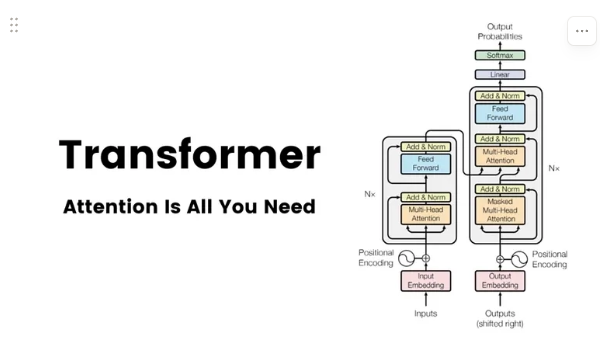  


**기존 Attnetion 기반의 Seq2Seq 구조** 
RNN으로 디코더와 디코더를 구현한 뒤, Attention을 추가한 구조  

- 왼쪽(인코더) : 입력 문장 이해  
- 오른쪽(디코더) : 출력 문장 이해  
- 회색 상자(층) 하나를 N개 쌓아 인코더와 디코더를 구성  

**기존 모델과 Transformer의 차이**  
인코더와 디코더 내부를 무엇으로 채워 구조(부품)를 만들었는가   

| 구분 | Seq2Seq + Attention | Transformer |
| --- | --- | --- |
| 인코더, 디코더의 내부 | LSTM (순차 처리) | Self-Attention |
| 어텐션의 역할 | RNN을 돕는 보조 역할 | 모델 그 자체 |
| 어텐션 사용 위치 | 디코더 → 인코더 1곳 | 인코더 내부, 디코더 내부, 인코더-디코더 사이 3곳 |
| 단어 순서 정보 | RNN이 순서대로 읽으며 반영 | Positional Encoding으로 따로 추가 |
| 병렬 처리 | 불가 | 가능 |    

- Transformer의 핵심 기술  
    
    - Self-Attention : 문장 안의 단어들이 서로 얼마나 참고해 중요한 관계를 맺고 있는지 한번에 문맥을 파악하는 기술  
    - Multi-Head Attention : Attention을 여러 갈래로 나눠 다양한 관점에서 관계를 파악  
    - Positional Econing : 각 단어의 위치를 벡터로 만들어 단어 벡터에 더하는 방법을 통해, 사라진 순서 정보를 보완  





## 2. Self-Attention   

### 2-1 Query, Key, Value  

**Review of Session03**
- RNN : 앞 뒤 내용이 서로 연관된 데이터에 대해 기억을 통해 이전 단계에서 처리한 정보를 현재 단계의 입력에 함께 활용하는 신경망  
    - RNN의 한계 : 장기의존성 문제(Vanishing gradient), Exploding gradient  

- LSTM : RNN의 기울기 소실 문제를 해결하고자 '중요한것은 오래 기억하고, 필요없는것은 잃어버리자'라는 아이디어에서 출발한 모델  
    - 장점  
        - 오래전에 입력된 정보들도 Cell state로 오래 기억 가능  
        - 가중치를 통한 곱셈이 거의 없어 gradient유지 가능  
        - 선택적으로 필요한 정보만 저장 및 삭제 가능  
    
    - 단점  
        - 3가지 게이트를 운용하므로, 계산이 복잡하고 시간이 오래 소요  
        - 여전히, 긴 문장에 있어서 기울기 소실 발생  

LSTM은 기억을 전달하는 방식을 개선 했지만, 순서대로 처리하는 구조 자체는 변화시키지 못함  

Transformer는 구조 자체를 바꾸어 순서대로 전달하는 대신 모든 단어를 서로 직접 비교  

-> 이때 단어끼리 비교하는데 쓰이는 재료가 **Query, Key, Value**  

**Attention 한줄 요약**
> Attention은 Query를 Key들과 비교해 관련도를 구하고, 그 비율만큼 Value를 섞어 결과를 만드는 계산  

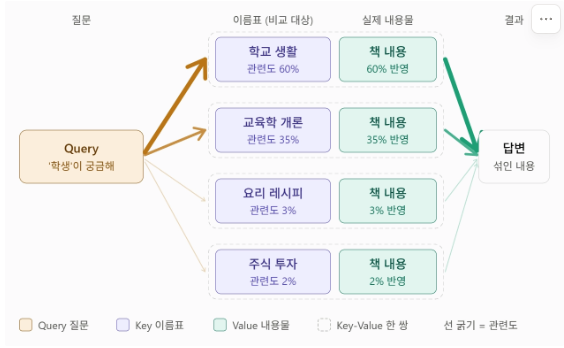  

1. Query(쿼리) : 현재 처리중인 단어가 다른 단어들에게 '지금 나에게 필요한 정보가 뭐지?'리고 묻는 벡터  

    *e.g.* '학생'에 대해 알고 싶어 라는 궁금증  

2. Key(키) : 각 단어가 '나는 이런 정보를 가지고 있어'라고 보이는 벡터. 즉, 키는 검색 대상이 되는 모든 정보의 '이름표'  

    *e.g.* '학교 생활', '교육학개론', '요리 레시피', '주식 투자' 제목 표 -> '학생'과 비교하여 60%, 35%, 3%, 2%  

3. Value(밸류) :  각 단어가 실제로 전달하는 정보 벡터. 관련도 비율만큼 모든 Value를 섞어 최종 결과를 만듦   

    *e.g.* 학교 생활 책 내용 60%, 교육학개론 35% + 요리 레시피 3% + 주식투자 2% -> 최종 답변  

- Key - Value 사이의 관계  
Key와 Value는 하나의 단어에서 함께 만들어진 한 쌍. Key : 찾을 때 쓰는 가준, Value : 찾았을때 가져오는 내용(like Python 문법)  
-> 그럼 Key와 Value는 왜 나눠요? 같은 단어라도 '무엇과 관련 있는지 판단할 때 필요한 정보'와 '실제로 전달해야할 정보'는 다를 수 있기 때문  


### 2-2 Cross-Attention vs Self-Attention  

**Preview**  
Seq2Seq의 Attention은 디코더가 인코더를 참고하는 Cross-Attention인 반면, Transformer는 문장이 자기 자신을 참고하는 Self-Attnetion  

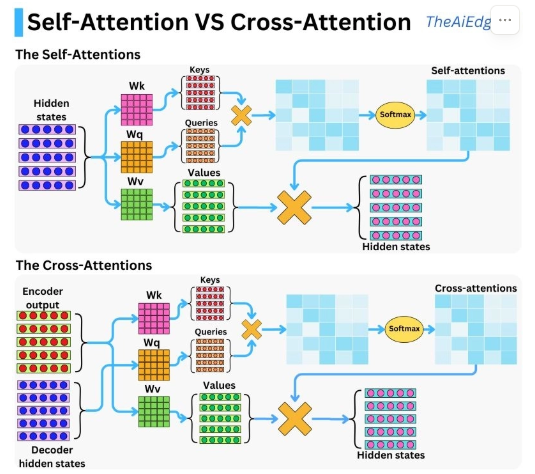  

- 공통 흐름  
    1. 입력된 학습을 변환 $W_k, W_q, W_v$에 통과시켜 Query, Key, Value생성  
    2. Query x Key(파란격자) -> 모든 단어 쌍의 관련도 표  
    3. softmax -> 각 줄 합이 1인 비율로 변환, 칸이 진할 수록 많이 참고  
    4. 비율 x Value -> 새로운 Hidden states  

- 차이점 : 
    - Self-Attention : Q, K, V가 모두 같은 입력 (같은 hidden states에서 생성)  
    - Cross-Attention : Q는 디코더 K, V는 인코더 출력에서 생성  

#### 기존의 Attention in Seq2Seq(Cross-Attention)  

Query와 Key-Value쌍이 서로 다른 시퀀스에서 출력  

Cross-Attention은 하나의 시퀀스가 독립된 다른 시퀀스를 참고하여 정보를 만들어내는 메커니즘 -> 디코더가 인코더에게 '지금 어디를 봐야하지?' 묻는 구조!  

> 핵심 과정 : (예시 : 원문 'The cat is sleeping' -> 번역 중 '고양이가 ____', 다음 단어를 만드는 순간)

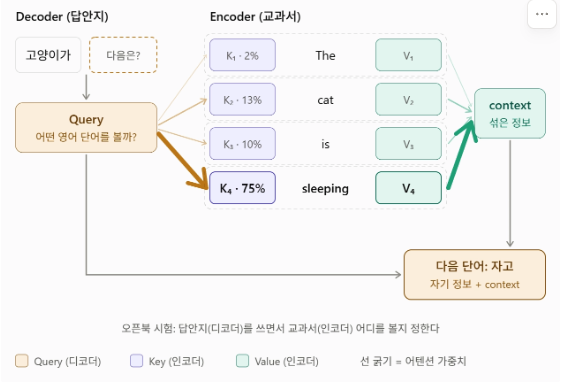  

1. Query 만들기 : 디코더가 지금까지 만든 '고양이가'를 바탕으로 현재 상태를 Query로 만듦 → 다음 단어를 위해 어떤 영어 단어를 봐야하는가?  

2. Key, Value 불러오기 : 인코더가 원문의 각 단어(The, cat, is, sleeping)에 대해 만들어 둔 벡터를 Key와 Value로 사용  

3. 유사도 계산(Attention Score) : 관련도 계산 $Q \cdot K_i$ (내적)  
Query와 각 Key의 관련도를 계산하고, softmax로 확률의 값 비율 변환 -> *e.g.*  The 2%, cat 13%, is 10%, sleeping 75%  

4. Weighted Sum  
비율만큼 Value를 섞어 Context Vector 생성 -> 디코더 자기 정보 + Context Vector로 다음 단어 '자고' 출력


#### 새로운 Attention (Self-Attention)  

Query와 Key - Value쌍이 같은 시퀀스에서 출력  
-> 문장이 스스로에게 '우리끼리 누가 누구와 관련이 있지?' 묻는 구조 (RNN없이도 문장 내부의 관계와 문맥 파악 가능)   

> 핵심 과정 : (예시 : '가을 은행 냄새 지독해'에서 '은행'의 의미 파악) 

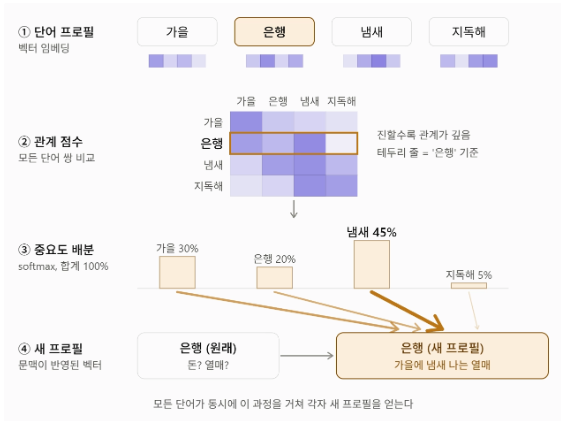


1. 벡터 임베딩 : 각 단어를 컴퓨터가 읽을 수 있도록 벡터로 변환하고 같은 벡터에서 Q, K, V를 생성  
    
2. 내적 및 관련도 점수 : '은행'의 Query와 모든 단어의 Key를 비교해 관계 점수 계산  


3. 중요도 배분 (Softmax & 어텐션 가중치) : 가을 30%, 은행 20%, **냄새 45%**, 지독해 5%로 비율 변환 및 특정 단어를 이해에 대한 각각의 %로 중요도 판단  
    
4. 새로운 벡터 생성 : 비율만큼 Value를 섞어 '은행'이 '돈? 열매?'에서 '가을에 냄새 나는 열매'라는 의미를 담은 새 벡터가 생성  

-> 이 과정을 모든 단어가 동시에 거쳐 각자 문맥이 완성된 새 백터를 얻음 -> **병렬 처리 가능!**  

**비교표**  

| 구분 | Cross-Attention | Self-Attention |
| --- | --- | --- |
| point | 번역 중인 문장이 원문을 참고 | 문장이 스스로 내부 관계를 파악 |
| 작동 방식 | 디코더의 Query로 인코더의 Key, Value를 조회 | 같은 문장에서 만든 Q, K, V로 모든 단어끼리 비교 |
| 참조 대상 | 서로 다른 시퀀스 (디코더 → 인코더) | 서로 같은 시퀀스 (문장 내부) |
| 주요 목적 | 고정 Context Vector의 병목 해결 | 문맥이 반영된 단어 표현 생성 |
| 결과 벡터 | Context Vector | 문맥이 반영된 새 표현 |
| 기반 아키텍처 | RNN | Transformer |
| 병렬처리 | RNN 기반일 때 불가능 | 가능 |  



### 2-3 Scaled Dot Product Attention  

#### Dot-Product Attention  
> Dot-Product? 2-1에서 Query와 Key를 비교해 관련도를 구할 때, '비교'의 계산 방법
Query와 Key 벡터를 내적하여 관련도 점수를 구하는 방식  

- Dot-Product Attention의 기본 과정  
1. Attention Score계산 : Query와 Key의 Transpose를 곱하여 모든 단어의 관련도 점수표 계산  

2. 계산된 값에 Softmax적용 -> Attention Weight 산출   
    
3. 최종 결과값 계산  
    - Attention Weight(6x6) x Value -> 각 단어가 다른 단어 정보를 비율만큼 섞은 새 백터 6개(행 기준)  

**문제점 : Attention Score의 극단화**  

벡터 차원이 커질수록 내적값이 지나치게 커질 가능성 존재. 이러한 값이 Softmax함수에 입력되면, 특정 단어에 확률이 과도하게 몰리는 현상 발생. Vanishing Gradient문제 발생 가능  


#### Scaled Dot-Product Attnetion  
기존의 Dot-Product Attention 문제를 해결한 방법 : 내적과 Softmax사이에 스케일링 단계 하나 추가  

- Sclaed Dot-Product Attention의 과정   
    1. Query와 모든 Key를 내적 -> Attention Score  
    2. Attention Score를 $\sqrt{d_k}$ 로 나누는 스케일링 과정 진행  
    3. Softmax적용하여 Attention Weight산출  
    4. Attention Weight x Value -> 최종 결과  

    - $\sqrt{d_k}$ 로 나누는 이유 : 분산이 다시 1근처로 돌아와, 차원 크기와 상관없이 점수가 안정적인 범위에 머물게 됨 *$\sqrt{d_k}$: dimension of key vector*

**Scaled Dot-Product Attention 계산의 결과로 얻어지는 벡터**  
- Cross-Attention : Context Vector  
    현재  생성 중인 단어에 필요한 원문 정보를 비율만큼 모은 벡터
- Self-Attention  
  문장 내 다른 단어들과의 관계가 반영되어 의미가 업데이트된 단어 벡터  



## 3. Multi-Head Attention  

### 3-1 Single-Head Attention VS Multi-Head Attention  

> 왜 Multi - Head Attention을 사용할까? 
> Head란? Attnetion 계산을 한 번 하는 독립된 단위  
    자기만의 가중치 행렬 세트 $W^Q, W^K, W^V$를 가지고 그 행렬로 Q,K,V를 만들어 Attention을 한 번 계산하고 결과 벡터 1개를 도출  
헤드마다 가중치 행렬의 숫자가 다르기 때문에 같은 문장을 보더라도 집중하는 단어가 달라짐  

#### Single-Head Attention(Head가 1개)  

- 가중치 행렬 세트 1개로, 512차원 벡터를 그대로 한번 Attention함 -> 단어마다 가중치 분포 1개 도출  

- 작동 방식  
    1. 각 단어의 512차원 벡터에 가중치 행렬 $W^Q, W^K, W^V$를 한 세트만 곱해서 Q, K, V를 생성  
    2. Q, K로 점수를 매기고, $\sqrt{d}$ 로 나눈 뒤, Softmax를 적용하여 가중치 분포 하나 얻음  
    3. 이 가중치로 V를 섞어서 512차원 벡터 하나 출력  

- 한계 : 집중력 100%를 혼자 나눠써야 한다  
    Softmax를 거친 가중치는 합이 항상 1(100%)인데, 한 단어를 이해하려면 여러 종류의 관계가 동시에 필요  
    헤드가 하나뿐이면 이 100%를 여러 관계에 골고루 나눠 줄 수밖에 없고, 결과는 여러 정보가 섞여 흐릿해진 벡터 하나가 됨  


#### Multi-Head Attention  

Attention을 작게 쪼개서 여러번 동시에 진행  

- 작동 방식   
    1. 512차원 벡터에 헤드마다 다른 $W^Q, W^K, W^V$를 곱해서 64차원 Q, K, V를 8세트 생성  
    2. 8개의 헤드가 서로 간섭하지 않고 각자 Attention계산(이때, 가중치 분포 8개 나옴)  
    3. 8개의 64차원 결과를 이어붙여(Concat방식) 다시 512차원을 생성  
    4. 마지막으로 $W^O$를 곱하여 8개의 관점을 하나로 섞음  

**e.g.** 'Tom gave Mary a book yesterday'
Multi-Head Attention: 헤드마다 각자 100%를 사용

| 헤드 | 주로 보는 단어 | 가중치 | 담당하는 질문 |
| --- | --- | --- | --- |
| 헤드 1 | Tom | 0.90 | Who? |
| 헤드 2 | Mary | 0.90 | To whom? |
| 헤드 3 | book | 0.90 | What? |
| 헤드 4 | yesterday | 0.90 | When? |  

-> 헤드마다 질문 하나에 집중하고, 결과를 나란히 이어 붙이기 때문에 네 정보가 섞이지 않고 또렷하게 남음  

**정리**  
- Single-Head : 기자 1명이 혼자 모든 질문을 다 취재해 기사 한 편을 쓰는 것. 모든 내용을 담지만 내용의 깊이가 얕음  
- Multi-Head : 기자 8명이 각자 한 분야만 깊게 취재하고, 편집장($W^O$)이 8편을 엮어 한 기사로 만드는 것


### 3-2 Multi-Head Attention 작동방식  

1. 분할 (Projection) - 8개의 관점 만들기
    - love라는 단어를 나타내는 512차원 벡터 하나에 헤드마다 다른 가중치 행렬을 곱해서, 64차원짜리 Q·K·V를 8세트를 생성  

2.  병렬 어텐션 계산 (Attention) - 각 헤드별 각자 분석
    - 8개 헤드가 서로 간섭하지 않고 동시에 Scaled Dot-Product Attention을 계산  
    > 이때 Head1에선 어떤 일이 일어나는가?  
    1. 점수 매기기(Score) : 
        love의 $Q_1$ 을 I, love, you의 $K_1$과 각각 내적하여 관련도 점수 3개를 계산  
    2. 크기 조절 (Scale):
        계산된 점수를 각 헤드 차원의 제곱근 ($\sqrt{64} = 8$)으로 나눔 (점수가 너무 커져 한 단어가 독차지하는 것을 방자)
    3. 가중치 변환 (Softmax):
        조절된 점수들에 Softmax를 적용하여 합이 1인 어텐션 가중치를 생성
        *e.g.* : I 0.2, love 0.7, you 0.1
    4. 섞기 (Weighted Sum):  
        이 가중치대로 I, love, you의 $V_1$에 곱해서 모두 더하면 **헤드 1의 결과 (64차원)** 가 도출 
    *헤드 2-8도 각자의 Q, K, V로 같은 계산을 동시에, 독립적으로 수행 -> 64차원 결과 8개 도출*

3. 이어 붙이기 (Concat)  
    - 8개의 64차원 결과를 순서대로 한 줄로 이어 붙여 512차원(8×64) 벡터를 하나 생성  

4. 섞기 (Final Projection)   
    - 이어 붙인 벡터는 아직 각 헤드의 분석 결과를 단순히 나열한 것, 따라서 이 벡터에 또 하나의 행렬 $W^O$(512x512)를 곱해 8개 관점을 하나의 의미로 융합  

=> 모든 단계 종료시 'love'라는 단어에 대한 Multi-Head Attention 레이어의 최종 출력 벡터를 얻게 됨!


## 4. Transformer 전체 아키텍쳐  

### 4-1 트랜스포머의 전처리 단계  

Transformer는 텍스트 입력(Inputs) -> 텍스트 토큰화 (Tokenization) -> 토큰 임베딩 (Embedding) -> Positional Encoding 순으로 동작  

1. 토큰화(Tokenization) : 문장을 모델이 다루는 기본 단위(토큰)로 자르는것을 의미  

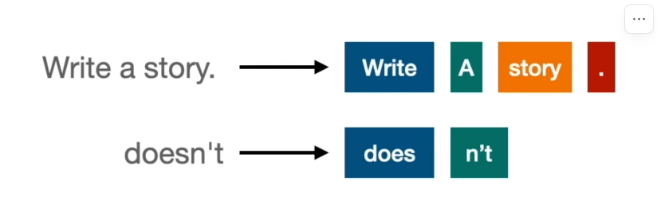  


- 보통 단어 하나 = 토큰 하나 : Give, me, an, apple  
- 문장 부호도 토큰 : . , !  
- 길거나 드문 단어는 여러 조각 : didn't -> did + n't  

2. 임베딩(Embedding) : 각 토큰을 숫자(벡터)로 변환  
    이때, 벡터의 길이 = 벡터의 차원

    - 임베딩의 원리 : 단어 -> 공간적 의미로 표현하는것  
    **핵심 원리** : 뜻이 비슷한 단어는 가까운 좌표에 놓인다  

- 임베딩 값은 처음엔 무작위이나 학습하면서 점점 의미에 맞는 자리를 찾아감  

3. Positional Encoding : 단어들의 순서 정보를 임베딩 벡터에 추가하는 단계  

- 왜 필요할까(Why)?  
    - Transformer는 모든 단어를 한꺼번에 보기 때문에, 그대로 두면 단어 순서를 모름  
    - '개는 고양이를 쫓는다'와 '고양이는 개를 쫓는다'를 다르다고 구분하지 못하고, 같은 단어 묶음으로 보게 됨  
    - RNN은 순서대로 읽어서 자연스럽게 알았지만, Transformer는 순서를 알려줘여함  

- 어떻게(How)?  
    - 각 위치마다 정해진 512차원 '위치 벡터'를 만들어 임베딩에 더함   
    -> 이때, 1번째 자리에는 항상 벡터 A, 2번째 자리에는 항상 벡터 B…처럼 문장이 달라도 규칙은 같아야 모델이 순서를 배울 수 있고 같은 단어라도 자리가 다르면 최종 벡터가 달라짐  




### 4-2 Encoder와 Decoder  

#### 1. Encoder : 원문을 깊이 이해하는 분석팀  

Encoder 층 하나는 두 부품으로 이루어짐  
1. Multi-Head Self-Attention : 원문 단어끼리 서로를 보며 문맥 파악  
2. Feed-Forward Network : 단어 하나하나를 따로 더 깊이 가공  

> FNN(FEed-Forward NetWork)란? $FFN(x) = max(0, xW_1 + b_1)W_2 + b_2  
- 512 차원을 2048차원으로 넓혔다가 다시 512차원으로 좁히는 2층 신경망, 사이에 ReLU가 들어감  
- 단어마다 따로, 같은 가중치로 적용, 이때 단어끼리 정보를 주고 받지 않음  
*Example*  
- Self-Attention = 조별 토론. 학생(단어)들이 서로의 의견을 들으며 생각을 업데이트  
- FFN = 토론이 끝난 뒤 받는 1:1 첨삭, 학생 한 명씩 같은 선생님에게 따로 가서 자기 노트를 다듬는 것  
    - 학생마다 따로 받음 -> 이 단계에서는 학생끼리 대화 X (단어별 독립 처리)  
    - 모든 학생이 같은 선생님에게 받음 -> 같은 가중치  
    - 선생님은 2048개 항목의 체크리스트로 노트를 꼼꼼히 따져보고(512 -> 2048), 해당 없는 항목은 지운 뒤(ReLU), 핵심만 다시 노트 한 장(512)으로 정리해 반환 (2048 -> 512)

**Adam & Norm** : 모든 부품에 붙는 안전장치  
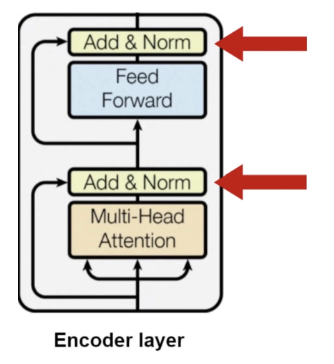  

- Add = Residual Connection (잔차 연결) 
    부품을 통과한 결과에 원래 입력을 그대로 더함. 앞선 CNN 모델 중 ResNet 모델에서 나온 아이디어  
    → 원본은 두고 수정 사항만 덧붙이는 원리 (원본 보존, 변경 내용만 덧붙이는 방식)  

- Norm = Layer Normalization (층 정규화) 
    한 단어 벡터안의 512개 숫자를 평균 0, 분산 1 근처로 맞춤
    -> 마이크 볼륨 맞추기는 원라. 발표자마다 마이크 볼륨이 제각각이면 듣기 힘들기 때문에 볼륨을 표준 레벨로 맞춰주는 과정 (학습을 안정적이고 빠르게 함)  


#### 2. Decoder : 번역문을 한 단어씩 쓰는 작성팀  

Decoder 층 하나는 세 부품으로 이루어짐  
1. Masked Multi-Head Self-Attention : 지금까지 쓴 번역 단어끼리 관계 파악 (미래 단어는 가림)  
2. Encoder-Decoder Attention (Cross-Attention) :원문 분석 자료(Encoder 출력)에서 필요한 부분 찾기  
3. Feed-Forward Network : Encoder와 동일  

세 부품 뒤에도 각각 Add&Norm이 붙으며, 6층을 다 통과하면 Linear + Softmax가 다음 단어의 확률을 계산  

**Masked Multi-Head Attention**  

> Masked Multi-Head Attention이란? Decoder의 Self-Attention에서 미래 시점의 단어 정보를 가려(Softmax 후 0) 자기보다 앞의 단어만 보게 하는 메커니즘  
- 역할  
    학습 때는 정답 문장 전체를 한 번에 넣어 병렬로 학습하는데, 마스크가 없으면 답을 미리 보고 맞히는 '컨닝'이 되는 현상 발생, 이를 막음
    e.g. 시험 볼 때 뒤 문제의 답안을 종이로 가려두는 것  

*Example(번역 모델)*   
나는 학교에 간다 -> I go to school  

디코더가 I go to를 입력받고 다음 단어를 예측할 때, 그 뒤에 나오는 단어인 school을 미리 보면 '컨닝'이 되기 때문에 학습이 부정확해짐 


**Encoder-Decoder Attention(Cross-Attention)**

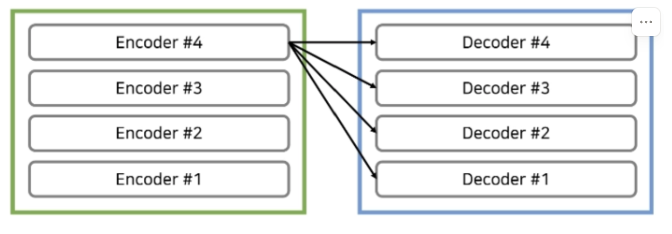  

> Encoder-Decoder Attention이란? 출력 문장 (Decoder)과 입력 문장 (Encoder)을 연결하는 과정 
- Q·K·V의 출처  
    - Q = 직전 Decoder 서브레이어의 출력  
    - K·V = Encoder 마지막 층의 출력 (6개 디코더 레이어가 모두 같은 Encoder 출력을 사용)  


**Example(번역 모델)**   
나는 학교에 간다 -> I go to school : Decoder가 'school'을 만들 차례라면  
    - Query : I go to 까지의 문맥을 담은 Decoder 상태
    - Key/Value : Encoder가 '나는 학교에 간다'를 인코딩한 벡터
    결과 : '학교' 부분에 높은 가중치를 주어, 한국어 입력의 의미와 영어 출력의 대응을 생성  
